# multimodel_analysis - Phase 5: more models and optional boosters
`run_all_models()` still runs the same standard set, so old code behaves identically. The new models are **opt-in**: pick them by name with `include=[...]` or run everything installed with `include='all'`.

| | classification | regression |
|---|---|---|
| new scikit-learn models | Extra Trees, Hist Gradient Boosting, MLP, LDA, Ridge Classifier, Linear SVM | Elastic Net, Bayesian Ridge, Huber, Linear SVR, Extra Trees, Hist Gradient Boosting, MLP |
| optional boosters | XGBoost, LightGBM, CatBoost | XGBoost, LightGBM, CatBoost |

Boosters need `pip install xgboost lightgbm catboost` (or `pip install multimodel_analysis[boost]`); if one is missing it is skipped by `include='all'` and reported with an install hint when you ask for it by name.

In [1]:
%matplotlib inline
import warnings
import pandas as pd
from sklearn.datasets import load_breast_cancer, load_iris, make_regression
import multimodel_analysis as mm
from multimodel_analysis import MultiModelClassifier, MultiModelRegressor
pd.set_option('display.width', 200)
print('multimodel_analysis', mm.__version__)

multimodel_analysis 0.4.0


## 1. What is available?

In [2]:
print('standard set      :', MultiModelClassifier.default_models())
print()
print('all classifiers    :', MultiModelClassifier.available_models())
print()
print('installed only     :', MultiModelClassifier.available_models(installed_only=True))
print()
print('all regressors     :', MultiModelRegressor.available_models())

standard set      : ['logistic_regression', 'svm', 'decision_tree', 'knn', 'naive_bayes', 'random_forest', 'gradient_boosting', 'adaboost']

all classifiers    : ['logistic_regression', 'svm', 'decision_tree', 'knn', 'naive_bayes', 'random_forest', 'gradient_boosting', 'adaboost', 'extra_trees', 'hist_gradient_boosting', 'mlp', 'lda', 'ridge_classifier', 'linear_svm', 'xgboost', 'lightgbm', 'catboost']

installed only     : ['logistic_regression', 'svm', 'decision_tree', 'knn', 'naive_bayes', 'random_forest', 'gradient_boosting', 'adaboost', 'extra_trees', 'hist_gradient_boosting', 'mlp', 'lda', 'ridge_classifier', 'linear_svm', 'xgboost', 'lightgbm', 'catboost']

all regressors     : ['linear_regression', 'lasso', 'ridge', 'svr', 'knn', 'decision_tree', 'random_forest', 'gradient_boosting', 'adaboost', 'elastic_net', 'bayesian_ridge', 'huber', 'linear_svr', 'extra_trees', 'hist_gradient_boosting', 'mlp', 'xgboost', 'lightgbm', 'catboost']


## 2. Backwards compatible: the default run is unchanged

In [3]:
bc = load_breast_cancer(as_frame=True)
clf = MultiModelClassifier(bc.data, bc.target, random_state=0, verbose=False)
standard = clf.run_all_models()
print([m[0] for m in standard])

['Logistic Regression', 'SVM', 'Decision Tree', 'KNN', 'Naive Bayes', 'Random Forest', 'Gradient Boosting', 'AdaBoost']


## 3. Run every installed classifier with `include='all'`

In [4]:
everything = clf.run_all_models(include='all')
df = clf.show_tabular_report(everything, sort_by='Accuracy', return_df=True)


 MODEL COMPARISON TABLE 
                       Model  Accuracy  Precision   Recall  F1 Score  ROC AUC  Fit Time (s)
                    CatBoost  0.964912   0.964912 0.964912  0.964912 0.986711      1.180673
         Logistic Regression  0.959064   0.959259 0.959064  0.959127 0.995619      0.005270
                         SVM  0.953216   0.953216 0.953216  0.953216 0.992699      0.008310
        Neural Network (MLP)  0.953216   0.953216 0.953216  0.953216 0.993137      0.300009
               Random Forest  0.953216   0.953187 0.953216  0.953062 0.978023      0.100666
Linear Discriminant Analysis  0.953216   0.953701 0.953216  0.952891 0.985543      0.001965
            Ridge Classifier  0.953216   0.953701 0.953216  0.952891 0.991822      0.003647
                     XGBoost  0.953216   0.953216 0.953216  0.953216 0.984083      0.270895
                  Linear SVM  0.947368   0.948433 0.947368  0.947597 0.995765      0.001436
      Hist Gradient Boosting  0.941520   0.941520 0.94

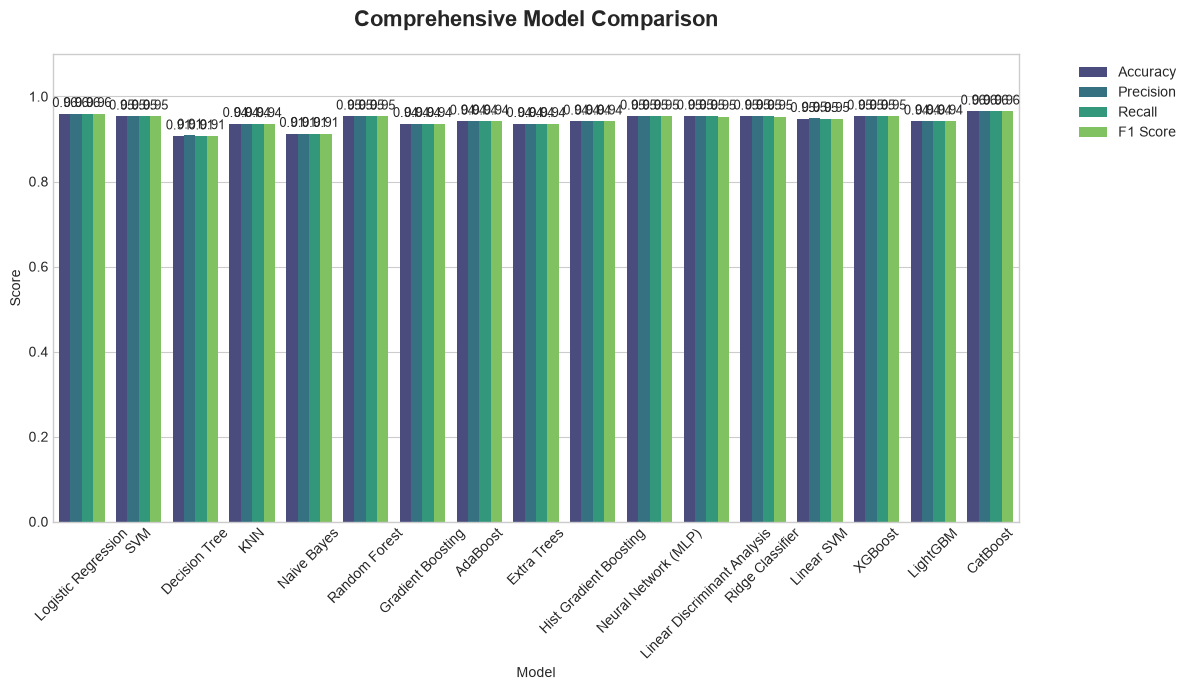

In [5]:
clf.plot_comparison(everything)

### Which models are fastest?

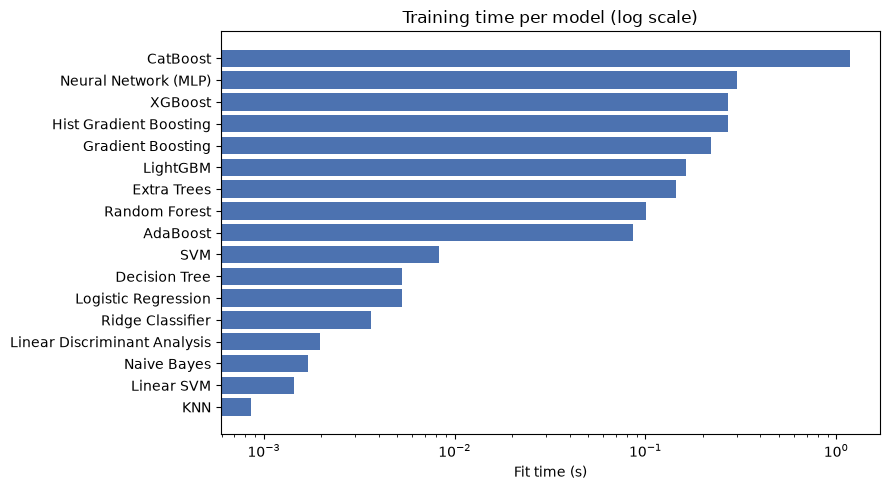

In [6]:
import matplotlib.pyplot as plt
t = df.sort_values('Fit Time (s)')
plt.figure(figsize=(9, 5))
plt.barh(t['Model'], t['Fit Time (s)'], color='#4C72B0')
plt.xlabel('Fit time (s)'); plt.title('Training time per model (log scale)'); plt.xscale('log'); plt.tight_layout(); plt.show()

## 4. Pick just the new models (names or keys, mixed with standard ones)

In [7]:
picked = clf.run_all_models(include=['random_forest', 'extra_trees', 'Linear SVM', 'lda'])
clf.show_tabular_report(picked, return_df=True)


 MODEL COMPARISON TABLE 
                       Model  Accuracy  Precision   Recall  F1 Score  ROC AUC  Fit Time (s)
               Random Forest  0.953216   0.953187 0.953216  0.953062 0.978023      0.134060
Linear Discriminant Analysis  0.953216   0.953701 0.953216  0.952891 0.985543      0.002450
                  Linear SVM  0.947368   0.948433 0.947368  0.947597 0.995765      0.001428
                 Extra Trees  0.935673   0.935533 0.935673  0.935569 0.988099      0.147895

* BEST MODEL RECOMMENDATION (by Accuracy): Random Forest
   Accuracy: 0.9532 | F1 Score: 0.9531



,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Fit Time (s)
0,Random Forest,0.953216,0.953187,0.953216,0.953062,0.978023,0.134060
1,Linear Discriminant Analysis,0.953216,0.953701,0.953216,0.952891,0.985543,0.002450
2,Linear SVM,0.947368,0.948433,0.947368,0.947597,0.995765,0.001428
3,Extra Trees,0.935673,0.935533,0.935673,0.935569,0.988099,0.147895


## 5. Boosters: XGBoost / LightGBM / CatBoost
They work with string labels, `predict`, tuning and `save_model` just like the built-in models.

In [8]:
iris = load_iris(as_frame=True)
y = iris.target.map(dict(enumerate(iris.target_names)))
ic = MultiModelClassifier(iris.data, y, random_state=1, verbose=False)
boost = [k for k in ['xgboost', 'lightgbm', 'catboost'] if k in MultiModelClassifier.available_models(installed_only=True)]
print('installed boosters:', boost)
m = ic.run_all_models(include=boost + ['random_forest'])
ic.show_tabular_report(m, return_df=True)

installed boosters: ['xgboost', 'lightgbm', 'catboost']



 MODEL COMPARISON TABLE 
        Model  Accuracy  Precision   Recall  F1 Score  ROC AUC  Fit Time (s)
Random Forest  0.977778   0.979167 0.977778  0.977753 0.991111      0.121286
     LightGBM  0.977778   0.979167 0.977778  0.977753 1.000000      0.114529
     CatBoost  0.977778   0.979167 0.977778  0.977753 1.000000      0.187300
      XGBoost  0.955556   0.956944 0.955556  0.955531 0.982222      0.311452

* BEST MODEL RECOMMENDATION (by Accuracy): Random Forest
   Accuracy: 0.9778 | F1 Score: 0.9778



,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Fit Time (s)
0,Random Forest,0.977778,0.979167,0.977778,0.977753,0.991111,0.121286
1,LightGBM,0.977778,0.979167,0.977778,0.977753,1.000000,0.114529
2,CatBoost,0.977778,0.979167,0.977778,0.977753,1.000000,0.187300
3,XGBoost,0.955556,0.956944,0.955556,0.955531,0.982222,0.311452


In [9]:
ic.predict(iris.data.sample(6, random_state=0), model='XGBoost' if 'xgboost' in boost else 'Random Forest')

array([np.str_('virginica'), np.str_('versicolor'), np.str_('setosa'),
       np.str_('virginica'), np.str_('setosa'), np.str_('virginica')],
      dtype=object)

### Tuning a booster (small custom grid)

In [10]:
ic.tune_models(include=boost[:1], search='grid', cv=3, param_grids={boost[0]: {'n_estimators': [50, 150], 'learning_rate': [0.05, 0.2]}})
ic.tuning_results_

,Model,Best CV accuracy,Best Params,Candidates,Search Time (s)
0,XGBoost,0.942857,"{'learning_rate': 0.05, 'n_estimators': 150}",4,2.010205


## 6. A missing optional package is explained, not a crash

In [11]:
from multimodel_analysis.core.registry import ModelRegistry, ModelSpec
from multimodel_analysis.supervised import CLASSIFIER_REGISTRY
ghost = ModelSpec('ghost', 'Ghost Booster', lambda ctx, **p: None, requires='no_such_package', default=False)

class WithGhost(MultiModelClassifier):
    registry = ModelRegistry(list(CLASSIFIER_REGISTRY) + [ghost])

g = WithGhost(bc.data, bc.target, verbose=False)
names = [m[0] for m in g.run_all_models(include='all')]
print('Ghost Booster' in names, '<- skipped by include="all"')
g.run_all_models(include=['ghost'])
print(g.failed_models_)

False <- skipped by include="all"
[WARNING] Model 'Ghost Booster' failed to train or evaluate: 'Ghost Booster' needs the optional package 'no_such_package'. Install it with: pip install no_such_package
{'Ghost Booster': "ImportError: 'Ghost Booster' needs the optional package 'no_such_package'. Install it with: pip install no_such_package"}


## 7. Regression: new linear models, MLP and boosters

In [12]:
Xr, yr = make_regression(n_samples=400, n_features=8, noise=12, random_state=2)
reg = MultiModelRegressor(Xr, yr, random_state=2, verbose=False)
rall = reg.run_all_models(include='all')
rdf = reg.show_tabular_report(rall, sort_by='RMSE', return_df=True)


 REGRESSION MODEL COMPARISON TABLE 
                           Model        MAE          MSE       RMSE  R2 Score  Fit Time (s)
                Ridge Regression   8.658229   118.952197  10.906521  0.996269      0.000459
                Lasso Regression   8.662584   119.478944  10.930642  0.996253      0.000480
                  Bayesian Ridge   8.671949   119.713715  10.941376  0.996245      0.000588
               Linear Regression   8.674467   119.763299  10.943642  0.996244      0.000465
                 Huber Regressor   8.703393   121.271561  11.012337  0.996197      0.005035
                      Linear SVR   8.664208   121.813041  11.036895  0.996180      0.005112
                     Elastic Net  11.485343   205.191959  14.324523  0.993565      0.000515
  Neural Network Regressor (MLP)  18.323702   548.464924  23.419328  0.982799      0.065717
                             SVR  32.534745  2328.788522  48.257523  0.926963      0.003093
              CatBoost Regressor  40.095968

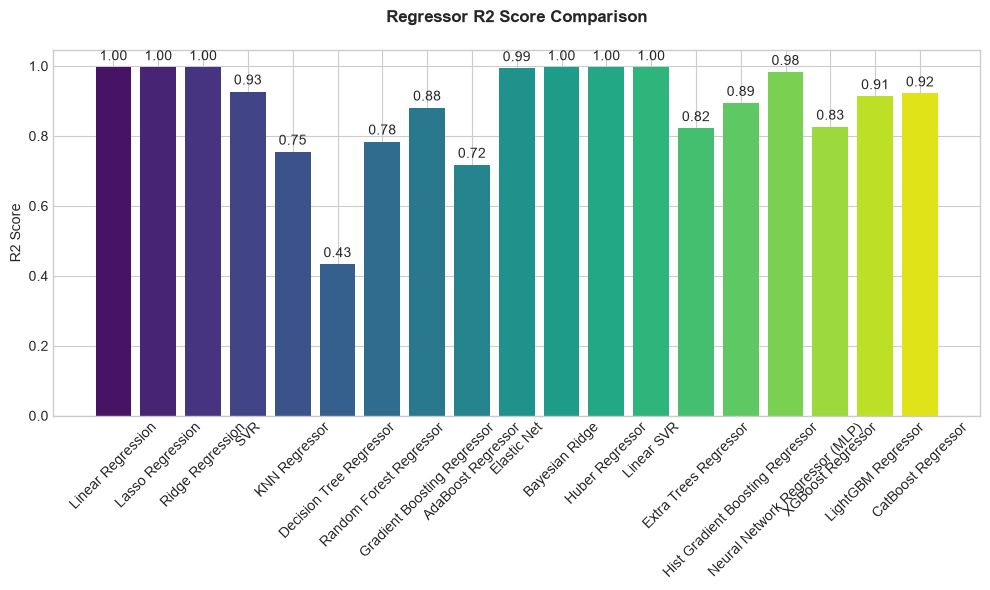

In [13]:
reg.plot_comparison(rall)

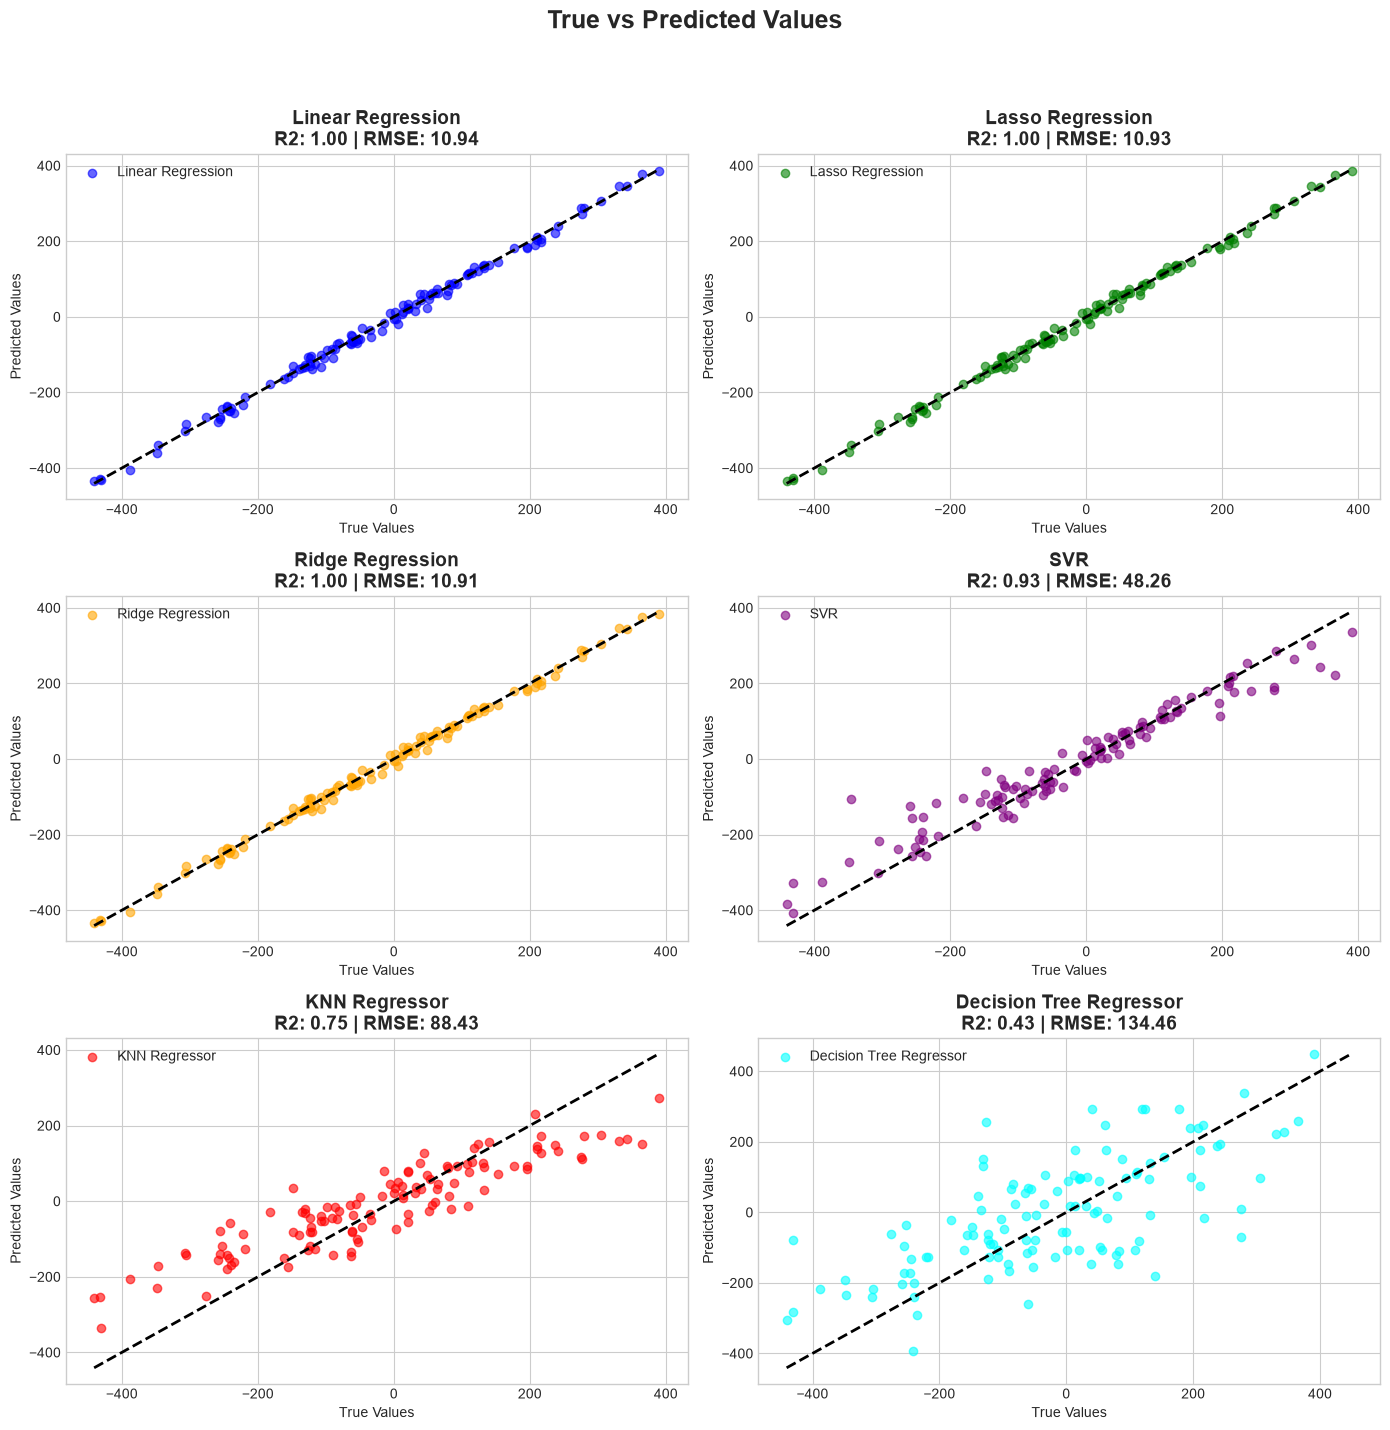

In [14]:
reg.plot_true_vs_predicted(rall[:6])

## 8. Imbalanced data: `class_weight='balanced'` reaches the new models too
The report's Recall is a weighted average (equal to accuracy), which hides the rare class, so here we measure the recall of the 5% minority class directly.

In [15]:
from sklearn.datasets import make_classification
from sklearn.metrics import recall_score
Xi, yi = make_classification(n_samples=1500, n_features=10, weights=[0.95, 0.05], flip_y=0, random_state=0)
rows = []
for cw in (None, 'balanced'):
    c = MultiModelClassifier(Xi, yi, class_weight=cw, random_state=0, verbose=False)
    for name, *_ in c.run_all_models(include=['extra_trees', 'linear_svm', 'ridge_classifier']):
        pred = c.get_model(name).predict(c.X_test_scaled)
        rows.append({'class_weight': str(cw), 'Model': name, 'minority recall': recall_score(c.y_test, pred, pos_label=1)})
pd.DataFrame(rows).pivot(index='Model', columns='class_weight', values='minority recall')

class_weight,None,balanced
Model,,
Extra Trees,0.681818,0.636364
Linear SVM,0.409091,0.954545
Ridge Classifier,0.090909,0.954545


## 9. Cross-validation and saving also work for the new models

In [16]:
cv = clf.cross_validate_models(include=['extra_trees', 'hist_gradient_boosting', 'mlp'], cv=5)
cv

,Model,accuracy mean,accuracy std,Fit Time (s)
0,Neural Network (MLP),0.979968,0.016942,0.150995
1,Extra Trees,0.972373,0.009407,0.141676
2,Hist Gradient Boosting,0.962278,0.008108,0.208610


In [17]:
import tempfile, os
clf.run_all_models(include=['hist_gradient_boosting'])
p = clf.save_model(os.path.join(tempfile.mkdtemp(), 'hgb.joblib'), model='Hist Gradient Boosting')
print(mm.load_model(p).predict(bc.data.head(5)), bc.target.head(5).tolist())

[0 0 0 0 0] [0, 0, 0, 0, 0]
